## Task 1: Import libraries and load the dataset

In [16]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

DATA_PATH = "Date_Fruit_Datasets.csv"

try:
    df = pd.read_excel(DATA_PATH)
except Exception:
    df = pd.read_csv(DATA_PATH, encoding="latin1")

df.columns = df.columns.str.strip()
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

Dataset shape: (898, 35)
Columns: ['AREA', 'PERIMETER', 'MAJOR_AXIS', 'MINOR_AXIS', 'ECCENTRICITY', 'EQDIASQ', 'SOLIDITY', 'CONVEX_AREA', 'EXTENT', 'ASPECT_RATIO', 'ROUNDNESS', 'COMPACTNESS', 'SHAPEFACTOR_1', 'SHAPEFACTOR_2', 'SHAPEFACTOR_3', 'SHAPEFACTOR_4', 'MeanRR', 'MeanRG', 'MeanRB', 'StdDevRR', 'StdDevRG', 'StdDevRB', 'SkewRR', 'SkewRG', 'SkewRB', 'KurtosisRR', 'KurtosisRG', 'KurtosisRB', 'EntropyRR', 'EntropyRG', 'EntropyRB', 'ALLdaub4RR', 'ALLdaub4RG', 'ALLdaub4RB', 'Class']


## Task 2: View and understand the dataset

In [17]:
display(df.head())

,AREA,PERIMETER,MAJOR_AXIS,MINOR_AXIS,ECCENTRICITY,EQDIASQ,SOLIDITY,CONVEX_AREA,EXTENT,ASPECT_RATIO,...,KurtosisRR,KurtosisRG,KurtosisRB,EntropyRR,EntropyRG,EntropyRB,ALLdaub4RR,ALLdaub4RG,ALLdaub4RB,Class
0,422163,2378.908,837.8484,645.6693,0.6373,733.1539,0.9947,424428,0.7831,1.2976,...,3.2370,2.9574,4.2287,-59191263232,-50714214400,-39922372608,58.7255,54.9554,47.8400,BERHI
1,338136,2085.144,723.8198,595.2073,0.5690,656.1464,0.9974,339014,0.7795,1.2161,...,2.6228,2.6350,3.1704,-34233065472,-37462601728,-31477794816,50.0259,52.8168,47.8315,BERHI
2,526843,2647.394,940.7379,715.3638,0.6494,819.0222,0.9962,528876,0.7657,1.3150,...,3.7516,3.8611,4.7192,-93948354560,-74738221056,-60311207936,65.4772,59.2860,51.9378,BERHI
3,416063,2351.210,827.9804,645.2988,0.6266,727.8378,0.9948,418255,0.7759,1.2831,...,5.0401,8.6136,8.2618,-32074307584,-32060925952,-29575010304,43.3900,44.1259,41.1882,BERHI
4,347562,2160.354,763.9877,582.8359,0.6465,665.2291,0.9908,350797,0.7569,1.3108,...,2.7016,2.9761,4.4146,-39980974080,-35980042240,-25593278464,52.7743,50.9080,42.6666,BERHI


In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 898 entries, 0 to 897
Data columns (total 35 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   AREA           898 non-null    int64  
 1   PERIMETER      898 non-null    float64
 2   MAJOR_AXIS     898 non-null    float64
 3   MINOR_AXIS     898 non-null    float64
 4   ECCENTRICITY   898 non-null    float64
 5   EQDIASQ        898 non-null    float64
 6   SOLIDITY       898 non-null    float64
 7   CONVEX_AREA    898 non-null    int64  
 8   EXTENT         898 non-null    float64
 9   ASPECT_RATIO   898 non-null    float64
 10  ROUNDNESS      898 non-null    float64
 11  COMPACTNESS    898 non-null    float64
 12  SHAPEFACTOR_1  898 non-null    float64
 13  SHAPEFACTOR_2  898 non-null    float64
 14  SHAPEFACTOR_3  898 non-null    float64
 15  SHAPEFACTOR_4  898 non-null    float64
 16  MeanRR         898 non-null    float64
 17  MeanRG         898 non-null    float64
 18  MeanRB    

In [19]:
display(df.describe(include='all').T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
AREA,898.0,NaN,NaN,NaN,298295.207127,107245.205337,1987.0,206948.0,319833.0,382573.0,546063.0
PERIMETER,898.0,NaN,NaN,NaN,2057.660953,410.012459,911.828,1726.0915,2196.34545,2389.716575,2811.9971
MAJOR_AXIS,898.0,NaN,NaN,NaN,750.811994,144.059326,336.7227,641.06865,791.3634,858.63375,1222.723
MINOR_AXIS,898.0,NaN,NaN,NaN,495.872785,114.268917,2.2832,404.684375,495.05485,589.0317,766.4536
ECCENTRICITY,898.0,NaN,NaN,NaN,0.737468,0.088727,0.3448,0.685625,0.7547,0.80215,1.0
EQDIASQ,898.0,NaN,NaN,NaN,604.577938,119.593888,50.2984,513.317075,638.14095,697.930525,833.8279
SOLIDITY,898.0,NaN,NaN,NaN,0.98184,0.018157,0.8366,0.978825,0.9873,0.9918,0.9974
CONVEX_AREA,898.0,NaN,NaN,NaN,303845.592428,108815.656947,2257.0,210022.75,327207.0,388804.0,552598.0
EXTENT,898.0,NaN,NaN,NaN,0.736267,0.053745,0.5123,0.705875,0.74695,0.77585,0.8562
ASPECT_RATIO,898.0,NaN,NaN,NaN,2.131102,17.820778,1.0653,1.373725,1.52415,1.67475,535.5257


## Task 3: Check data quality and class balance

In [20]:
print("Missing values per column:")
display(df.isnull().sum().sort_values(ascending=False).to_frame("Missing values"))
print("Duplicate rows:", df.duplicated().sum())
print("\nClass counts:")
display(df["Class"].value_counts().to_frame("Samples"))

Missing values per column:


,Missing values
AREA,0
PERIMETER,0
MAJOR_AXIS,0
MINOR_AXIS,0
ECCENTRICITY,0
EQDIASQ,0
SOLIDITY,0
CONVEX_AREA,0
EXTENT,0
ASPECT_RATIO,0


Duplicate rows: 0

Class counts:


,Samples
Class,
DOKOL,204
SAFAVI,199
ROTANA,166
DEGLET,98
SOGAY,94
IRAQI,72
BERHI,65


## Task 4: Clean data and select features/target

In [21]:
df = df.drop_duplicates().copy()
df = df.dropna(subset=["Class"])
target = "Class"
X = df.drop(columns=[target])
y = df[target].astype(str).str.strip()

X = X.apply(pd.to_numeric, errors="coerce")
print("Cleaned dataset shape:", df.shape)
print("Number of input features:", X.shape[1])
print("Target classes:", sorted(y.unique()))

Cleaned dataset shape: (898, 35)
Number of input features: 34
Target classes: ['BERHI', 'DEGLET', 'DOKOL', 'IRAQI', 'ROTANA', 'SAFAVI', 'SOGAY']


## Task 5: Split into training and testing sets

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Training set:", X_train.shape)
print("Testing set :", X_test.shape)
print("\nTraining class distribution:")
display(y_train.value_counts().to_frame("Samples"))

Training set: (718, 34)
Testing set : (180, 34)

Training class distribution:


,Samples
Class,
DOKOL,163
SAFAVI,159
ROTANA,133
DEGLET,78
SOGAY,75
IRAQI,58
BERHI,52


## Task 6: Build and train the Logistic Regression model

In [23]:
model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=5000, class_weight=None))
])

model.fit(X_train, y_train)
print("Model training complete.")

Model training complete.


## Task 7: Make predictions

In [24]:
y_pred = model.predict(X_test)
results = pd.DataFrame({
    "Actual Class": y_test.to_numpy(),
    "Predicted Class": y_pred
})
results["Correct?"] = np.where(
    results["Actual Class"] == results["Predicted Class"], "Yes", "No"
)
display(results.head(20))

,Actual Class,Predicted Class,Correct?
0,SAFAVI,SAFAVI,Yes
1,DOKOL,DOKOL,Yes
2,SAFAVI,SAFAVI,Yes
3,DOKOL,DOKOL,Yes
4,SAFAVI,SAFAVI,Yes
5,DOKOL,DOKOL,Yes
6,ROTANA,ROTANA,Yes
7,BERHI,BERHI,Yes
8,DOKOL,DOKOL,Yes
9,SAFAVI,SAFAVI,Yes


## Task 8: Evaluate model performance

In [25]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="weighted", zero_division=0)
recall = recall_score(y_test, y_pred, average="weighted", zero_division=0)
f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)

print(f"Test Accuracy          : {accuracy:.4f}")
print(f"Weighted Precision     : {precision:.4f}")
print(f"Weighted Recall        : {recall:.4f}")
print(f"Weighted F1 Score      : {f1:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Test Accuracy          : 0.9278
Weighted Precision     : 0.9262
Weighted Recall        : 0.9278
Weighted F1 Score      : 0.9263

Classification Report:
              precision    recall  f1-score   support

       BERHI       1.00      0.92      0.96        13
      DEGLET       0.83      0.75      0.79        20
       DOKOL       0.95      0.95      0.95        41
       IRAQI       0.93      1.00      0.97        14
      ROTANA       0.94      0.97      0.96        33
      SAFAVI       0.95      1.00      0.98        40
       SOGAY       0.83      0.79      0.81        19

    accuracy                           0.93       180
   macro avg       0.92      0.91      0.92       180
weighted avg       0.93      0.93      0.93       180



## Task 9: Confusion matrix

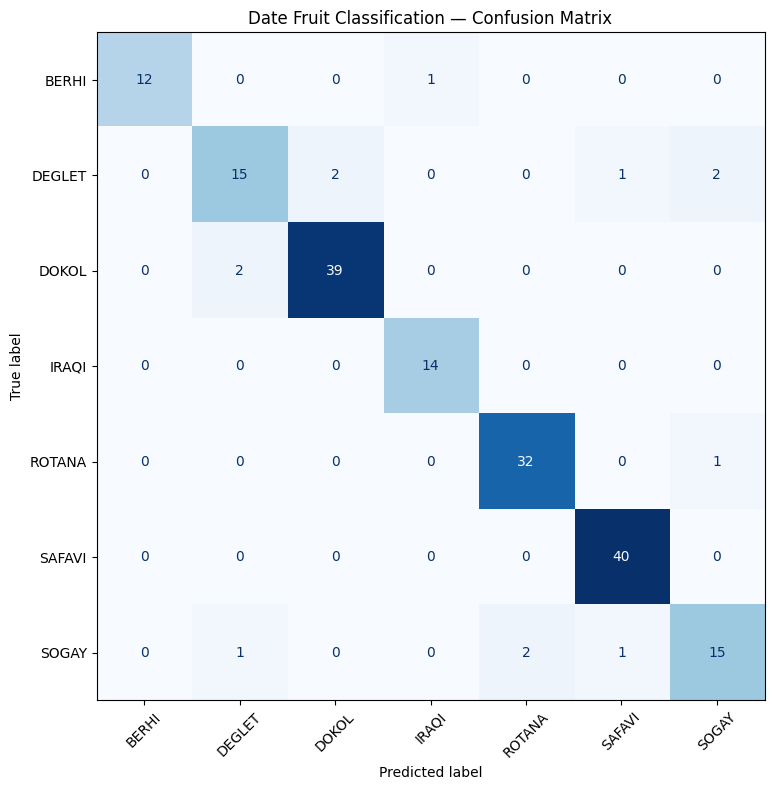

In [26]:
labels = model.named_steps["classifier"].classes_
cm = confusion_matrix(y_test, y_pred, labels=labels)
fig, ax = plt.subplots(figsize=(10, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False)
plt.title("Date Fruit Classification — Confusion Matrix")
plt.tight_layout()
plt.show()

## Task 10: Cross-validation

In [27]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = cross_validate(
    model, X, y, cv=cv,
    scoring={"accuracy": "accuracy", "precision": "precision_weighted",
             "recall": "recall_weighted", "f1": "f1_weighted"}
)
for metric in ["accuracy", "precision", "recall", "f1"]:
    values = cv_results[f"test_{metric}"]
    print(f"{metric.title():10s}: {values.mean():.4f} ± {values.std():.4f}")

Accuracy  : 0.9254 ± 0.0159
Precision : 0.9272 ± 0.0158
Recall    : 0.9254 ± 0.0159
F1        : 0.9239 ± 0.0164


## Task 11: Predict the class of a new date fruit

In [28]:

new_fruit = X.iloc[[0]].copy()
predicted_class = model.predict(new_fruit)[0]
class_probabilities = model.predict_proba(new_fruit)[0]

print("Predicted date-fruit class:", predicted_class)
display(pd.DataFrame({
    "Class": model.named_steps["classifier"].classes_,
    "Probability": class_probabilities
}).sort_values("Probability", ascending=False).reset_index(drop=True))

Predicted date-fruit class: BERHI


,Class,Probability
0,BERHI,9.613639e-01
1,ROTANA,2.846695e-02
2,IRAQI,8.842102e-03
3,SOGAY,1.325552e-03
4,DEGLET,1.408514e-06
5,SAFAVI,9.767553e-08
6,DOKOL,8.704537e-11


## Task 12: Save the trained model

In [29]:
import joblib

MODEL_PATH = "date_fruit_logistic_regression.joblib"
joblib.dump(model, MODEL_PATH)
print(f"Saved model to: {MODEL_PATH}")

loaded_model = joblib.load(MODEL_PATH)
print("Reload prediction:", loaded_model.predict(X_test.iloc[:5]))

Saved model to: date_fruit_logistic_regression.joblib
Reload prediction: ['SAFAVI' 'DOKOL' 'SAFAVI' 'DOKOL' 'SAFAVI']


## Task 13: GRADIO INTERFACE


In [30]:
!pip install gradio

In [31]:
import gradio as gr
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

df = pd.read_excel("Date_Fruit_Datasets.csv")

X = df.drop("Class", axis=1)
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=5000)
)

model.fit(X_train, y_train)

def predict_fruit(*values):
    input_df = pd.DataFrame([values], columns=X.columns)

    prediction = model.predict(input_df)[0]
    probabilities = model.predict_proba(input_df)[0]

    confidence = {
        str(cls): float(prob)
        for cls, prob in zip(model.classes_, probabilities)
    }

    return f"Predicted Date Fruit: {prediction}", confidence

inputs = [
    gr.Number(label=column, value=float(X[column].median()))
    for column in X.columns
]

demo = gr.Interface(
    fn=predict_fruit,
    inputs=inputs,
    outputs=[
        gr.Textbox(label="Predicted Class"),
        gr.Label(label="Class Probabilities")
    ],
    title="Date Fruit Classification",
    description=(
        "Enter the 34 physical and visual measurements "
        "to predict the date fruit variety using Logistic Regression."
    )
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://eba16f5c3fe0b0cd42.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
